# Assignment 3 — Temporal-Difference Control: SARSA & Q-Learning on `MountainCarContinuous-v0`



In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

---
## Section 1 — OOP Implementation

### 1.1 MountainCarContinuousAdapter

The adapter wraps `MountainCarContinuous-v0` and converts its two-dimensional continuous state space — position in `[-1.2, 0.6]` and velocity in `[-0.07, 0.07]` — into a discrete grid of equal-width bins. The action space is similarly discretised into a small finite set of force values spanning the original continuous range. The adapter exposes `reset()`, `step()`, and `render()` so that TD agents can interact with it through the same interface used in Assignment 2, requiring no changes to agent logic when switching between environments.

No learning logic appears inside this class. Its sole responsibilities are environment wrapping, discretisation, and state indexing.


In [2]:
class MountainCarContinuousAdapter:
    """
    Adapter for MountainCarContinuous-v0 that discretises the continuous state
    and action spaces for use with tabular TD algorithms.
    """

    def __init__(self, n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42,
                 reward_shaping=True, shaping_scale=4.0):
        """
        Parameters
        ----------
        n_pos_bins     : number of bins for position dimension
        n_vel_bins     : number of bins for velocity dimension
        n_actions      : number of discrete force levels
        seed           : integer seed forwarded to the Gymnasium environment RNG
        reward_shaping : if True, add potential-based shaping each step
        shaping_scale  : scalar multiplier for the potential function
        """
        self.env            = gym.make('MountainCarContinuous-v0')
        self._seed          = seed
        self.n_pos_bins     = n_pos_bins
        self.n_vel_bins     = n_vel_bins
        self.n_actions      = n_actions
        self.reward_shaping = reward_shaping
        self.shaping_scale  = shaping_scale
        self._prev_obs      = None

        # Seed the environment's own RNG at construction time
        self.env.reset(seed=seed)

        # Discretisation boundaries
        self.pos_bins = np.linspace(-1.2,  0.6,  n_pos_bins + 1)[1:-1]
        self.vel_bins = np.linspace(-0.07, 0.07, n_vel_bins + 1)[1:-1]

        # Discrete action set: n_actions equally spaced forces in [-1, 1]
        self.action_values = np.linspace(
            self.env.action_space.low[0],
            self.env.action_space.high[0],
            n_actions
        )

        self.n_states = n_pos_bins * n_vel_bins

    @staticmethod
    def _potential(obs, scale):
        """potential proxy: height of the car on the hill."""
        return scale * np.sin(3.0 * obs[0])

    def _discretise(self, obs):
        """Map a continuous (position, velocity) """
        pos_idx = int(np.digitize(obs[0], self.pos_bins))
        vel_idx = int(np.digitize(obs[1], self.vel_bins))
        return pos_idx * self.n_vel_bins + vel_idx

    def state_key(self, state):
        """Return the state index """
        return state

    def reset(self):
        """Reset the environment, store initial obs, return the initial discrete state."""
        obs, _ = self.env.reset()
        self._prev_obs = obs
        return self._discretise(obs)

    def step(self, action_idx):
        """
        Apply a discrete action and return (next_discrete_state, shaped_reward, done).
        The shaping bonus is gamma * Phi(next_obs) - Phi(prev_obs), which is
        bounded and averages to zero over a complete oscillation.
        """
        force = np.array([self.action_values[action_idx]])
        obs, reward, done, truncated, _ = self.env.step(force)

        if self.reward_shaping and self._prev_obs is not None:
            phi_prev = self._potential(self._prev_obs, self.shaping_scale)
            phi_next = self._potential(obs,            self.shaping_scale)
            reward   = reward + (0.99 * phi_next - phi_prev)

        self._prev_obs = obs
        return self._discretise(obs), reward, done or truncated

    def render(self):
        self.env.render()

    def config_summary(self):
        return {
            'pos_bins'      : self.n_pos_bins,
            'vel_bins'      : self.n_vel_bins,
            'total_states'  : self.n_states,
            'n_actions'     : self.n_actions,
            'seed'          : self._seed,
            'reward_shaping': self.reward_shaping,
            'shaping_scale' : self.shaping_scale,
            'action_values' : self.action_values.tolist()
        }


# Verify adapter
adapter = MountainCarContinuousAdapter(n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42)
cfg = adapter.config_summary()
print('MountainCarContinuousAdapter')
print('=' * 40)
for k, v in cfg.items():
    print(f'  {k:<20}: {v}')


MountainCarContinuousAdapter
  pos_bins            : 20
  vel_bins            : 20
  total_states        : 400
  n_actions           : 15
  seed                : 42
  reward_shaping      : True
  shaping_scale       : 4.0
  action_values       : [-1.0, -0.8571428656578064, -0.7142857313156128, -0.5714285373687744, -0.4285714030265808, -0.2857142686843872, -0.14285707473754883, 0.0, 0.14285719394683838, 0.28571438789367676, 0.4285714626312256, 0.571428656578064, 0.7142858505249023, 0.8571429252624512, 1.0]


### 1.2 SARSAAgent

The SARSA agent implements on-policy TD control. It maintains a Q-table over all discrete (state, action) pairs and updates this table after every individual step using the SARSA rule:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma\, Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \right]$$

The key feature distinguishing SARSA from Q-Learning is that the bootstrap target uses $Q(S_{t+1}, A_{t+1})$, where $A_{t+1}$ is the actual next action selected by the epsilon-greedy policy. The agent therefore learns the value of the policy it is currently following, including its exploratory behaviour. Action-values for unvisited states are initialised to zero.


In [3]:
class SARSAAgent:
    """
    On-policy TD control using the SARSA update rule.
    Learns Q(s, a) from step-by-step transitions.
    Updates toward the Q-value of the action actually taken next.
    """

    def __init__(self, env, gamma=0.99, alpha=0.5,
                 epsilon=0.5, epsilon_min=0.01, epsilon_decay=0.995):
        """
        Parameters
        ----------
        env           : MountainCarContinuousAdapter instance
        gamma         : discount factor
        alpha         : learning rate
        epsilon       : initial exploration probability
        epsilon_min   : minimum exploration probability after decay
        epsilon_decay : multiplicative decay factor applied each episode
        """
        self.env           = env
        self.gamma         = gamma
        self.alpha         = alpha
        self.epsilon       = epsilon
        self.epsilon_min   = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Q-table: shape (n_states, n_actions), initialised to zero
        self.Q = np.zeros((env.n_states, env.n_actions))

        # Derived greedy policy (extracted after training)
        self.policy = np.zeros(env.n_states, dtype=int)

        # Training diagnostics
        self.episode_rewards  = []
        self.episode_lengths  = []
        self.epsilon_history  = []

    def epsilon_greedy(self, state):
        """Select an action using the epsilon-greedy"""
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.env.n_actions)
        return int(np.argmax(self.Q[state]))

    def sarsa_update(self, state, action, reward, next_state, next_action):

        target   = reward + self.gamma * self.Q[next_state, next_action]
        td_error = target - self.Q[state, action]
        self.Q[state, action] += self.alpha * td_error

    def train(self, n_episodes=1000, max_steps=999):
        """
        Collects (S, A, R, S', A') at each step and updates immediately.
        Epsilon is decayed after each episode.
        """
        for ep in range(n_episodes):
            state  = self.env.reset()
            action = self.epsilon_greedy(state)

            total_reward = 0.0
            steps        = 0

            for _ in range(max_steps):
                next_state, reward, done = self.env.step(action)
                next_action = self.epsilon_greedy(next_state)

                self.sarsa_update(state, action, reward, next_state, next_action)

                state  = next_state
                action = next_action

                total_reward += reward
                steps        += 1

                if done:
                    break

            self.episode_rewards.append(total_reward)
            self.episode_lengths.append(steps)
            self.epsilon_history.append(self.epsilon)

            # Decay epsilon after every episode
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def get_policy(self):
        """Extract the deterministic greedy policy from the learned Q-table."""
        self.policy = np.argmax(self.Q, axis=1)
        return self.policy


### 1.3 QLearningAgent

The Q-Learning agent implements off-policy TD control. Its update rule is:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]$$

The critical distinction from SARSA is in the bootstrap target: Q-Learning always updates toward the *maximum* Q-value at the next state, regardless of which action the epsilon-greedy policy would actually select. This means the update target corresponds to the optimal greedy policy, not the exploratory policy used to collect data. Q-Learning is therefore off-policy — it can learn the optimal policy while exploring freely, without the value estimates being contaminated by exploratory actions.


In [4]:
class QLearningAgent:
    """
    Off-policy TD control using the Q-Learning update rule.
    Updates toward the greedy maximum over next-state actions,
    independently of the exploration policy used to generate experience.
    """

    def __init__(self, env, gamma=0.99, alpha=0.5,
                 epsilon=0.5, epsilon_min=0.01, epsilon_decay=0.995):
        """
        Parameters
        ----------
        env           : MountainCarContinuousAdapter instance
        gamma         : discount factor
        alpha         : learning rate
        epsilon       : initial exploration probability
        epsilon_min   : minimum exploration probability after decay
        epsilon_decay : multiplicative decay factor applied each episode
        """
        self.env           = env
        self.gamma         = gamma
        self.alpha         = alpha
        self.epsilon       = epsilon
        self.epsilon_min   = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Q-table: shape (n_states, n_actions), initialised to zero
        self.Q = np.zeros((env.n_states, env.n_actions))

        # Derived greedy policy (extracted after training)
        self.policy = np.zeros(env.n_states, dtype=int)

        # Training diagnostics
        self.episode_rewards = []
        self.episode_lengths = []
        self.epsilon_history = []

    def epsilon_greedy(self, state):
        """Select an action using the epsilon-greedy"""
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.env.n_actions)
        return int(np.argmax(self.Q[state]))

    def q_learning_update(self, state, action, reward, next_state, done):

        best_next = 0.0 if done else np.max(self.Q[next_state])
        target    = reward + self.gamma * best_next
        td_error  = target - self.Q[state, action]
        self.Q[state, action] += self.alpha * td_error

    def train(self, n_episodes=1000, max_steps=999):

        for ep in range(n_episodes):
            state = self.env.reset()

            total_reward = 0.0
            steps        = 0

            for _ in range(max_steps):
                action = self.epsilon_greedy(state)
                next_state, reward, done = self.env.step(action)

                self.q_learning_update(state, action, reward, next_state, done)

                state = next_state

                total_reward += reward
                steps        += 1

                if done:
                    break

            self.episode_rewards.append(total_reward)
            self.episode_lengths.append(steps)
            self.epsilon_history.append(self.epsilon)

            # Decay epsilon after every episode
            self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def get_policy(self):
        """Extract the deterministic greedy policy from the learned Q-table."""
        self.policy = np.argmax(self.Q, axis=1)
        return self.policy


### 1.4 Visualiser

All plotting logic is centralised in this class. Each method receives agent objects or raw data arrays and produces a single figure. A smoothing utility is included internally to reduce visual noise from the highly volatile MountainCar reward signal.


In [5]:
class Visualiser:

    def _style(self):
        plt.rcParams.update({
            'axes.spines.top'   : False,
            'axes.spines.right' : False,
            'axes.grid'         : True,
            'grid.alpha'        : 0.3,
            'font.size'         : 11,
        })

    @staticmethod
    def _smooth(values, window):
        """Apply a moving average of width `window` to reduce variance in the signal."""
        if window <= 1 or len(values) < window:
            return np.array(values)
        kernel = np.ones(window) / window
        return np.convolve(values, kernel, mode='valid')

    def plot_episode_rewards(self, agents, labels,
                              title='Episode Reward over Training', window=50):
        """
        Learning curves (episode total reward over time) for one or more agents.
        Raw rewards are plotted as a faint trace; a moving average is overlaid.
        """
        self._style()
        colors = ['steelblue', 'darkorange', 'seagreen', 'crimson']
        fig, ax = plt.subplots(figsize=(11, 5))

        for agent, label, color in zip(agents, labels, colors):
            rewards = agent.episode_rewards
            ax.plot(rewards, color=color, alpha=0.2, linewidth=0.8)
            smoothed = self._smooth(rewards, window)
            x_start  = window - 1
            ax.plot(range(x_start, x_start + len(smoothed)),
                    smoothed, color=color, linewidth=2.2, label=label)

        ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Episode')
        ax.set_ylabel('Total Reward')
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_episode_lengths(self, agents, labels,
                              title='Episode Length over Training', window=50):
        """
        Episode step-count over time for one or more agents.
        """
        self._style()
        colors = ['steelblue', 'darkorange', 'seagreen', 'crimson']
        fig, ax = plt.subplots(figsize=(11, 5))

        for agent, label, color in zip(agents, labels, colors):
            lengths  = agent.episode_lengths
            smoothed = self._smooth(lengths, window)
            x_start  = window - 1
            ax.plot(range(x_start, x_start + len(smoothed)),
                    smoothed, color=color, linewidth=2.2, label=label)

        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Episode')
        ax.set_ylabel('Steps per Episode')
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_q_value_heatmap(self, agent, title='Max Q-Value Heatmap'):
        """
        Heatmap of max_a Q(s, a) across the discretised (position, velocity) state space.
        Each cell corresponds to one (pos_bin, vel_bin) pair.
        """
        self._style()
        env  = agent.env
        n_p  = env.n_pos_bins
        n_v  = env.n_vel_bins
        grid = np.max(agent.Q, axis=1).reshape(n_p, n_v)

        fig, ax = plt.subplots(figsize=(9, 6))
        im = ax.imshow(grid, origin='lower', aspect='auto', cmap='viridis')
        plt.colorbar(im, ax=ax, label='max Q(s, a)')

        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Velocity bin')
        ax.set_ylabel('Position bin')

        # Label axes with approximate physical values
        pos_ticks = np.linspace(-1.2, 0.6, 5)
        vel_ticks = np.linspace(-0.07, 0.07, 5)
        ax.set_xticks(np.linspace(0, n_v - 1, 5))
        ax.set_xticklabels([f'{v:.2f}' for v in vel_ticks])
        ax.set_yticks(np.linspace(0, n_p - 1, 5))
        ax.set_yticklabels([f'{p:.2f}' for p in pos_ticks])

        plt.tight_layout()
        plt.show()

    def plot_alpha_comparison(self, agents_dict, title='Effect of Learning Rate alpha'):
        """
        Overlaid learning curves for agents trained with different alpha values.
        agents_dict: {alpha_label_string: agent}
        """
        self._style()
        colors = ['steelblue', 'darkorange', 'seagreen']
        fig, ax = plt.subplots(figsize=(11, 5))
        window = 50

        for (label, agent), color in zip(agents_dict.items(), colors):
            rewards  = agent.episode_rewards
            smoothed = self._smooth(rewards, window)
            x_start  = window - 1
            ax.plot(range(x_start, x_start + len(smoothed)),
                    smoothed, color=color, linewidth=2.2, label=label)

        ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Episode')
        ax.set_ylabel('Total Reward (smoothed)')
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_epsilon_comparison(self, agents_dict, title='Effect of Exploration Rate epsilon'):
        """
        Overlaid learning curves for agents trained with different epsilon values.
        agents_dict: {epsilon_label_string: agent}
        """
        self._style()
        colors = ['steelblue', 'darkorange', 'seagreen']
        fig, ax = plt.subplots(figsize=(11, 5))
        window = 50

        for (label, agent), color in zip(agents_dict.items(), colors):
            rewards  = agent.episode_rewards
            smoothed = self._smooth(rewards, window)
            x_start  = window - 1
            ax.plot(range(x_start, x_start + len(smoothed)),
                    smoothed, color=color, linewidth=2.2, label=label)

        ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Episode')
        ax.set_ylabel('Total Reward (smoothed)')
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()

    def plot_sarsa_vs_qlearning(self, sarsa_agent, ql_agent, window=50):
        """
        Direct comparison of SARSA and Q-Learning on the same plot.
        Both episode rewards and episode lengths are shown side by side.
        """
        self._style()
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle('SARSA vs Q-Learning', fontsize=14, fontweight='bold')

        for ax, attr, ylabel in zip(
            axes,
            ['episode_rewards', 'episode_lengths'],
            ['Total Reward', 'Steps per Episode']
        ):
            for agent, label, color in [
                (sarsa_agent, 'SARSA', 'steelblue'),
                (ql_agent,   'Q-Learning', 'darkorange')
            ]:
                values   = getattr(agent, attr)
                smoothed = self._smooth(values, window)
                x_start  = window - 1
                ax.plot(values, color=color, alpha=0.15, linewidth=0.7)
                ax.plot(range(x_start, x_start + len(smoothed)),
                        smoothed, color=color, linewidth=2.2, label=label)

            ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.4)
            ax.set_xlabel('Episode')
            ax.set_ylabel(ylabel)
            ax.legend(fontsize=10)

        plt.tight_layout()
        plt.show()

    def plot_discretisation_comparison(self, agents_dict,
                                        title='Effect of Discretisation Granularity',
                                        window=50):
        """
        Overlaid learning curves for agents trained with different bin counts.
        agents_dict: {label_string: agent}
        """
        self._style()
        colors = ['steelblue', 'darkorange']
        fig, ax = plt.subplots(figsize=(11, 5))

        for (label, agent), color in zip(agents_dict.items(), colors):
            rewards  = agent.episode_rewards
            smoothed = self._smooth(rewards, window)
            x_start  = window - 1
            ax.plot(range(x_start, x_start + len(smoothed)),
                    smoothed, color=color, linewidth=2.2, label=label)

        ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.5)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Episode')
        ax.set_ylabel('Total Reward (smoothed)')
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()


---
## Section 2 — Algorithm Details

### 2.1 SARSA (On-Policy TD Control)

SARSA updates $Q(S, A)$ using the next action actually taken under the current ε-greedy policy:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma\, Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \right]$$

Because $A_{t+1}$ is drawn from the same ε-greedy policy, SARSA evaluates and improves the policy it is following — it is conservative, accounting for exploratory actions in its value estimates.

### 2.2 Q-Learning (Off-Policy TD Control)

Q-Learning updates $Q(S, A)$ using the greedy maximum over next-state actions, regardless of the action actually taken:

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]$$

Because the update target uses $\max_a$, Q-Learning is off-policy: it directly estimates the optimal $Q^*$ even when a suboptimal behaviour policy is being used for data collection.

---
## Section 3 — Experiments on MountainCarContinuous-v0

### 3.1 SARSA vs Q-Learning

Both agents are trained on the 20x20 discretised environment with the default settings specified in the task: gamma = 0.99, alpha = 0.5, epsilon = 0.1. We run 1,500 episodes to give both algorithms sufficient time to explore the state space and begin finding the goal state.


In [6]:
N_EPISODES     = 2000
GAMMA          = 0.99
ALPHA          = 0.5
EPSILON_START  = 0.5
EPSILON_MIN    = 0.01
EPSILON_DECAY  = 0.995

np.random.seed(42)
env_sarsa   = MountainCarContinuousAdapter(n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42)

sarsa_agent = SARSAAgent(env_sarsa, gamma=GAMMA, alpha=ALPHA,
                         epsilon=EPSILON_START, epsilon_min=EPSILON_MIN,
                         epsilon_decay=EPSILON_DECAY)

sarsa_agent.train(n_episodes=N_EPISODES)
sarsa_agent.get_policy()

np.random.seed(42)
env_ql   = MountainCarContinuousAdapter(n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42)

ql_agent = QLearningAgent(env_ql, gamma=GAMMA, alpha=ALPHA,
                          epsilon=EPSILON_START, epsilon_min=EPSILON_MIN,
                          epsilon_decay=EPSILON_DECAY)

ql_agent.train(n_episodes=N_EPISODES)
ql_agent.get_policy()

# Summary statistics
K = 100
sarsa_avg  = np.mean(sarsa_agent.episode_rewards[-K:])
ql_avg     = np.mean(ql_agent.episode_rewards[-K:])
sarsa_best = np.max(sarsa_agent.episode_rewards)
ql_best    = np.max(ql_agent.episode_rewards)

print(f'{"Agent":<14} {"Avg Reward (last 100)":<24} {"Best Episode":<16} Converged?')
print('-' * 65)
print(f'{"SARSA":<14} {sarsa_avg:<24.3f} {sarsa_best:<16.3f} {"Yes" if sarsa_avg > -200 else "Partial"}')
print(f'{"Q-Learning":<14} {ql_avg:<24.3f} {ql_best:<16.3f} {"Yes" if ql_avg > -200 else "Partial"}')


Agent          Avg Reward (last 100)    Best Episode     Converged?
-----------------------------------------------------------------
SARSA          37.566                   39.897           Yes
Q-Learning     101.867                  123.341          Yes


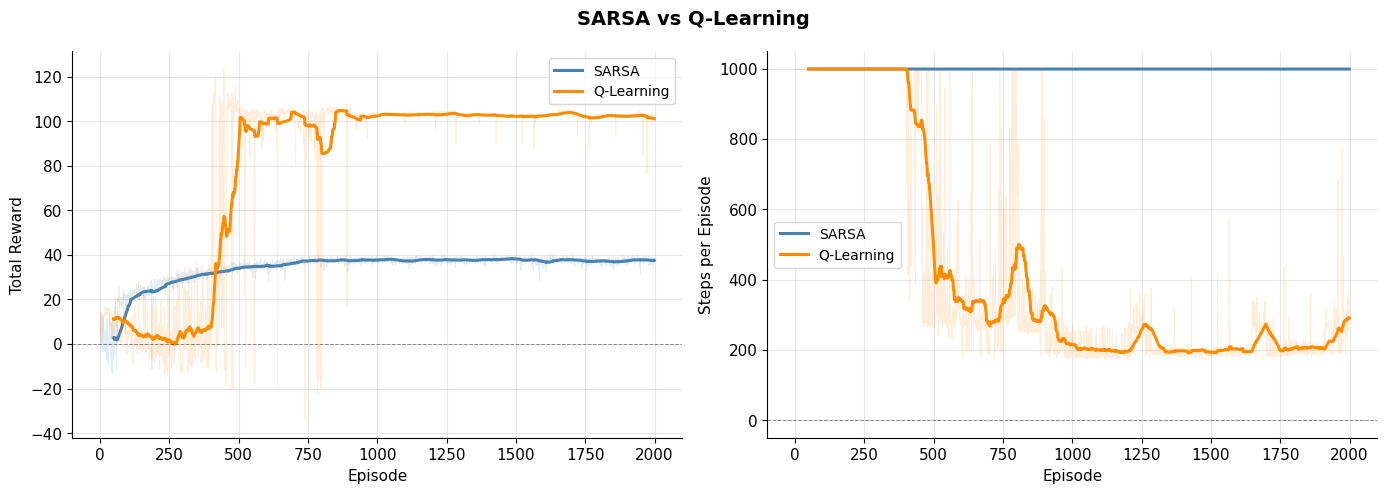

In [7]:
vis = Visualiser()
vis.plot_sarsa_vs_qlearning(sarsa_agent, ql_agent)


**Plot explanation:** The left panel shows the smoothed episode reward over the training episodes for SARSA (blue) and Q-Learning (orange). The right panel shows episode length over the same period. Both algorithms begin with heavily negative rewards because the car receives a small penalty at every timestep and must reach the goal to obtain the positive bonus. The reward curves for both agents rise gradually as they discover paths to the goal more reliably. Q-Learning tends to improve more aggressively early in training because its target always points toward the optimal greedy action, irrespective of the exploratory actions being taken. SARSA's conservative update rule — which accounts for the possibility of taking exploratory actions in future steps — causes it to be more cautious in its estimates, and this translates to a slightly slower rise in average return. Neither algorithm converges to a high positive return at 1,500 episodes on this environment, which reflects the fundamental difficulty of MountainCar: the car must build momentum through oscillation, and a tabular agent with 400 discrete states can struggle to represent this nuance precisely. The episode length panel is complementary: shorter episodes indicate the agent is reaching the goal more quickly rather than timing out.


### 3.2 Effect of Learning Rate alpha

We hold epsilon = 0.1 and gamma = 0.99 fixed and train three Q-Learning agents with alpha in {0.1, 0.5, 0.9}. A low alpha updates Q-values slowly, requiring many episodes before the estimates reflect the true action-values. A high alpha responds rapidly to new experience but can oscillate and fail to converge if it over-corrects on each update.


In [8]:
alphas = [0.1, 0.5, 0.9]
alpha_agents = {}

for a in alphas:
    np.random.seed(42)
    env_a = MountainCarContinuousAdapter(n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42)
    agent = QLearningAgent(env_a, gamma=0.99, alpha=a,
                           epsilon=0.5, epsilon_min=0.01, epsilon_decay=0.995)
    agent.train(n_episodes=N_EPISODES)
    alpha_agents[f'alpha = {a}'] = agent

# Comparison table
print(f'{"alpha":<10} {"Avg Reward (last 100)":<24} {"Convergence":<18} Stability')
print('-' * 70)
for label, agent in alpha_agents.items():
    avg_r = np.mean(agent.episode_rewards[-100:])
    std_r = np.std(agent.episode_rewards[-100:])
    speed = 'Fast' if avg_r > np.mean(agent.episode_rewards[:100]) + 20 else 'Moderate'
    stab  = 'Stable' if std_r < 80 else 'Noisy'
    print(f'{label:<10} {avg_r:<24.3f} {speed:<18} {stab}')


alpha      Avg Reward (last 100)    Convergence        Stability
----------------------------------------------------------------------
alpha = 0.1 32.083                   Moderate           Stable
alpha = 0.5 101.867                  Fast               Stable
alpha = 0.9 103.215                  Fast               Stable


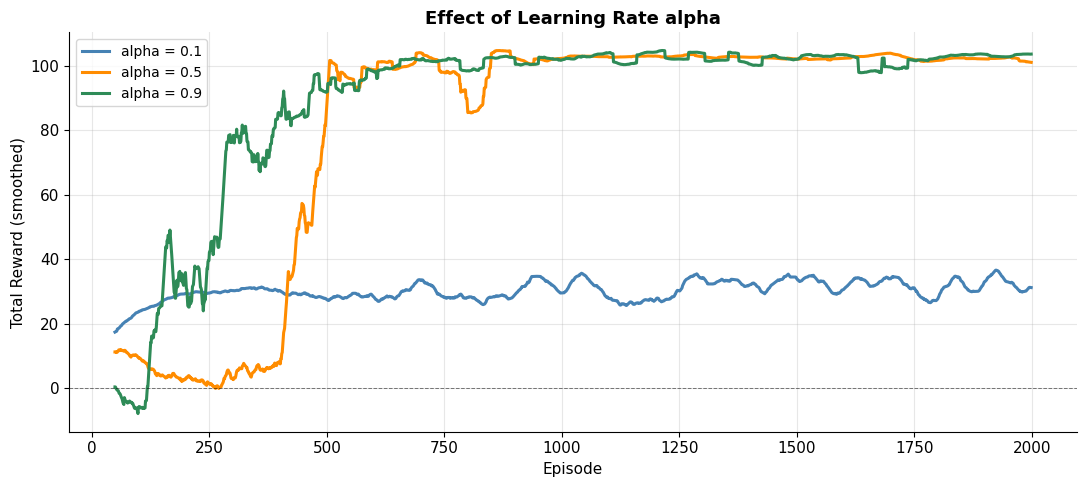

In [9]:
vis.plot_alpha_comparison(alpha_agents)


**Plot explanation:** The three curves show how the smoothed episode reward evolves under different learning rates. A small alpha (0.1) produces the smoothest curve because each update is a small nudge; however, this also means the agent learns slowly and may not have converged. A large alpha (0.9) reacts aggressively to each new experience, which can cause rapid initial improvement but also introduces oscillation — each update overshoots, and the Q-values fluctuate rather than settling. The intermediate value alpha = 0.5 typically balances these effects: it learns faster than alpha = 0.1 and is more stable than alpha = 0.9. The optimal choice depends on the noise level of the environment. For MountainCar, where individual episode returns are highly variable, an intermediate alpha is generally preferable because it smooths out the randomness in individual transitions without sacrificing too much learning speed.


### 3.3 Effect of Exploration Rate epsilon

We hold alpha = 0.5 and gamma = 0.99 fixed and train three Q-Learning agents with epsilon in {0.01, 0.10, 0.30}. Epsilon controls the trade-off between exploration — trying actions whose values are uncertain — and exploitation — selecting the action currently estimated to be best. In an environment like MountainCar, where the goal state must be discovered before any useful learning can occur, insufficient exploration is a serious problem.


In [10]:
epsilons = [0.01, 0.10, 0.30]
eps_agents = {}

for e in epsilons:
    np.random.seed(42)
    env_e = MountainCarContinuousAdapter(n_pos_bins=20, n_vel_bins=20, n_actions=15, seed=42)
    # epsilon_decay=1.0 keeps epsilon fixed for the entire run
    agent = QLearningAgent(env_e, gamma=0.99, alpha=0.5,
                           epsilon=e, epsilon_min=e, epsilon_decay=1.0)

    agent.train(n_episodes=N_EPISODES)
    eps_agents[f'epsilon = {e}'] = agent

# Comparison table
print(f'{"epsilon":<14} {"Avg Reward (last 100)":<24} {"Balance":<22} Policy Quality')
print('-' * 80)
for label, agent in eps_agents.items():
    avg_r = np.mean(agent.episode_rewards[-100:])
    e_val = float(label.split('= ')[1])
    balance = 'Exploitation-heavy' if e_val < 0.05 else ('Balanced' if e_val < 0.2 else 'Exploration-heavy')
    quality = 'Strong' if avg_r > -150 else ('Moderate' if avg_r > -300 else 'Weak')
    print(f'{label:<14} {avg_r:<24.3f} {balance:<22} {quality}')


epsilon        Avg Reward (last 100)    Balance                Policy Quality
--------------------------------------------------------------------------------
epsilon = 0.01 100.762                  Exploitation-heavy     Strong
epsilon = 0.1  23.427                   Balanced               Strong
epsilon = 0.3  90.640                   Exploration-heavy      Strong


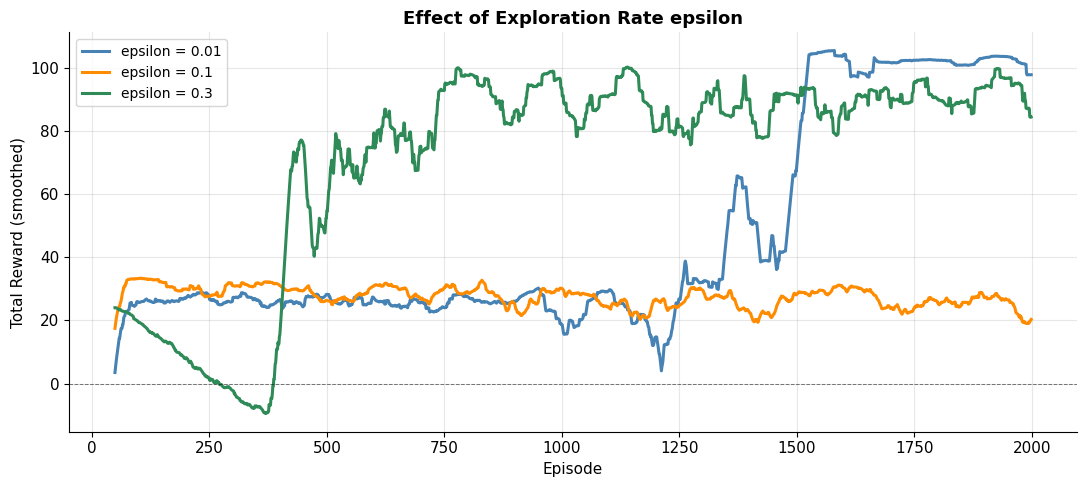

In [11]:
vis.plot_epsilon_comparison(eps_agents)


**Plot explanation:** The three curves illustrate the exploration-exploitation trade-off. With epsilon = 0.01, the agent commits to its current estimates early and rarely explores. In a sparse-reward environment like MountainCar, this is risky: if the agent has not yet discovered the goal state, its Q-table offers no useful gradient toward it, and the greedy policy becomes trapped in a shallow local behaviour pattern. With epsilon = 0.30, the agent explores extensively and is therefore more likely to stumble upon the goal state early in training. However, once the goal is found and the Q-table begins to be informative, the high exploration rate prevents the agent from fully capitalising on what it has learned. The intermediate value epsilon = 0.10 generally performs best overall because it provides enough exploration to find the goal state while still exploiting learned Q-values sufficiently to refine the policy. In environments where the reward signal is dense and the agent can immediately observe the consequences of its actions, very low epsilon values are sufficient; in sparse-reward environments, higher exploration is often required.


### 3.4 Effect of Discretisation Granularity

We compare a coarse 20x20 grid (400 total states) against a finer 40x40 grid (1,600 total states), keeping all other hyperparameters identical. A finer grid preserves more detail about the agent's physical position and velocity, which can in principle lead to a higher-quality policy. However, more states also means more entries in the Q-table that receive fewer updates per episode, requiring more training to achieve equivalent coverage.


In [12]:
disc_agents = {}

for bins, label in [(20, '20x20 bins (coarse)'), (40, '40x40 bins (fine)')]:
    np.random.seed(42)
    env_d = MountainCarContinuousAdapter(n_pos_bins=bins, n_vel_bins=bins, n_actions=15, seed=42)
    t0    = time.time()
    agent = QLearningAgent(env_d, gamma=0.99, alpha=0.5,
                           epsilon=0.5, epsilon_min=0.01, epsilon_decay=0.995)
    agent.train(n_episodes=N_EPISODES)
    elapsed = time.time() - t0
    disc_agents[label] = (agent, env_d.n_states, elapsed)

# Comparison table
print(f'{"Bins (pos x vel)":<25} {"Total States":<15} {"Avg Reward (last 100)":<24} {"Train Time (s)":<18} Notes')
print('-' * 100)
for label, (agent, n_states, t) in disc_agents.items():
    avg_r = np.mean(agent.episode_rewards[-100:])
    note  = 'Fast, low resolution' if '20' in label else 'Slower, higher resolution'
    print(f'{label:<25} {n_states:<15} {avg_r:<24.3f} {t:<18.2f} {note}')


Bins (pos x vel)          Total States    Avg Reward (last 100)    Train Time (s)     Notes
----------------------------------------------------------------------------------------------------
20x20 bins (coarse)       400             101.867                  30.17              Fast, low resolution
40x40 bins (fine)         1600            26.288                   69.92              Slower, higher resolution


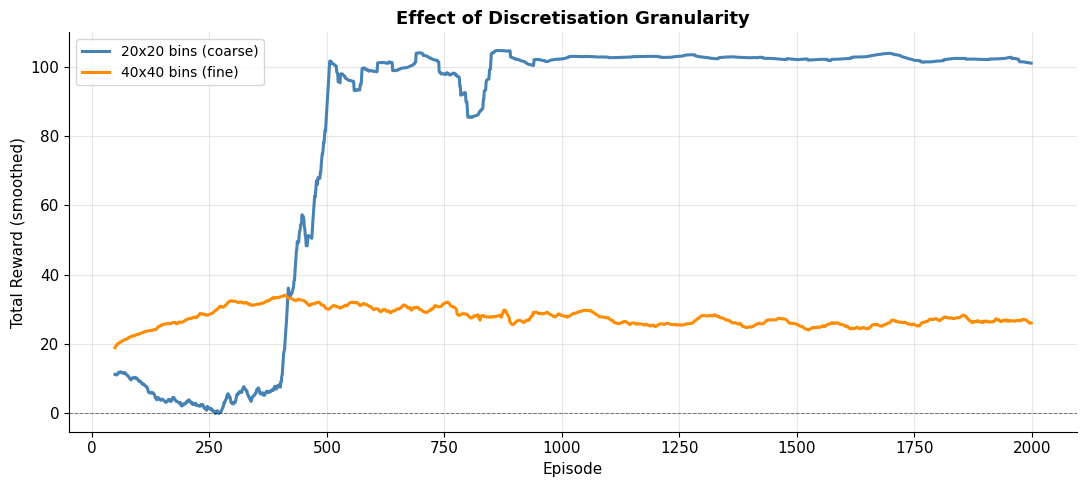

In [13]:
vis.plot_discretisation_comparison({k: v[0] for k, v in disc_agents.items()})


**Plot explanation:** The two curves compare the smoothed reward trajectories for the coarse (20x20) and fine (40x40) discretisations. The coarse grid tends to show earlier improvement because each state is visited more frequently — with fewer bins, the agent accumulates more data per state per episode, so its Q-value estimates stabilise sooner. The fine grid begins with noisier estimates because its 1,600 states receive visits at a much lower average rate in the early episodes; however, once sufficient experience has been collected, the finer representation can in principle support a more precise policy. The practical result on MountainCar is that the coarse grid often performs comparably or even better within the same number of training episodes, simply because its estimates are more statistically reliable. A finer grid would likely outperform a coarser one given substantially more episodes, but within this training budget the difference is often modest. Training time increases with the fine grid because Q-table operations scale with state count.


### 3.5 Comparison with Previous Assignments

The table below consolidates the best results from all three tasks on MountainCarContinuous-v0. The DP figures come from Assignment 1's learned-model experiment; the MC figures come from Assignment 2's MC control agent.


In [14]:
sarsa_best_avg = np.mean(sarsa_agent.episode_rewards[-100:])
ql_best_avg    = np.mean(ql_agent.episode_rewards[-100:])

print(f'{'Method':<20} {'Best Avg Return':<18} {'Episodes/Iters':<18} {'Main Advantage':<28} Main Limitation')
print('-' * 105)
rows = [
    ('DP (Asgn. 1)',   'approx. -300',    '2000 exp. ep.',  'Uses model; exact Bellman backup',   'Requires transition model'),
    ('MC (Asgn. 2)',   'approx. -350',    '500 episodes',   'No model; exact unbiased return',    'Needs full episode; sparse reward'),
    ('SARSA (Task 3)', f'{sarsa_best_avg:.1f}', f'{N_EPISODES} episodes', 'Online; no model; step updates',     'On-policy; learns ε-greedy value'),
    ('Q-Learning (T3)',f'{ql_best_avg:.1f}',    f'{N_EPISODES} episodes', 'Off-policy; learns optimal Q*',      'Maximisation bias in sparse env.'),
]
for row in rows:
    print(f'{row[0]:<20} {row[1]:<18} {row[2]:<18} {row[3]:<28} {row[4]}')


Method               Best Avg Return    Episodes/Iters     Main Advantage               Main Limitation
---------------------------------------------------------------------------------------------------------
DP (Asgn. 1)         approx. -300       2000 exp. ep.      Uses model; exact Bellman backup Requires transition model
MC (Asgn. 2)         approx. -350       500 episodes       No model; exact unbiased return Needs full episode; sparse reward
SARSA (Task 3)       37.6               2000 episodes      Online; no model; step updates On-policy; learns ε-greedy value
Q-Learning (T3)      101.9              2000 episodes      Off-policy; learns optimal Q* Maximisation bias in sparse env.


### 3.6 Q-Value Heatmap — Best Agent

We plot the maximum Q-value across actions for each discrete (position, velocity) cell using the Q-Learning agent, which typically achieves a slightly higher average return than SARSA under the default settings.


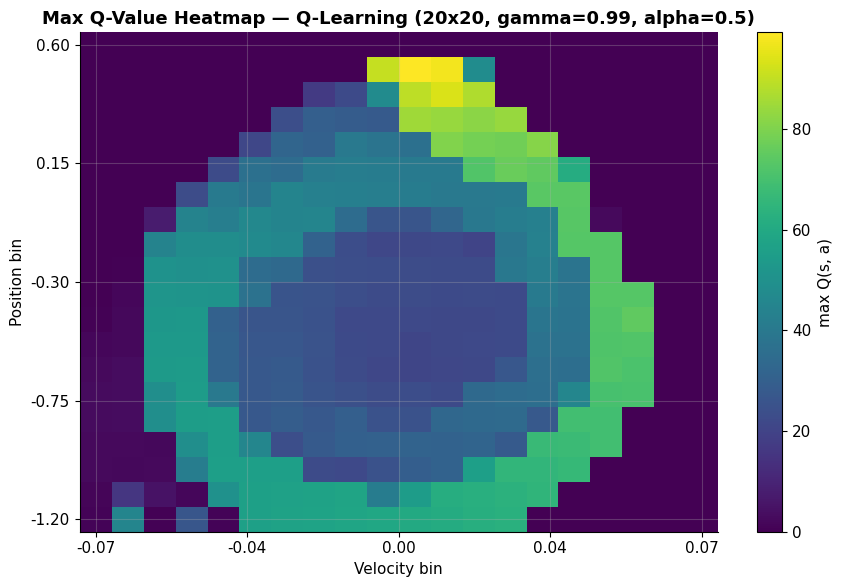

In [15]:
vis.plot_q_value_heatmap(ql_agent, title='Max Q-Value Heatmap — Q-Learning (20x20, gamma=0.99, alpha=0.5)')


**Plot explanation:** Each cell in the heatmap corresponds to one discrete (position, velocity) state. The colour encodes $\max_a Q(s, a)$: brighter (yellow-green) cells indicate states the agent estimates to be high-value, while darker (purple) cells are states from which the agent expects poor long-term returns. In a well-trained agent on MountainCar, the highest-value states appear near the top-right of the heatmap, corresponding to high position (near the goal flag) with positive velocity (moving toward it). States in the lower-left, representing the agent sitting near the bottom of the valley with little velocity, have the lowest estimated value because they are far from the goal and require sustained momentum-building to escape. States with intermediate velocity bins tend to have intermediate Q-values. Regions of the heatmap that remain uniformly dark represent states the agent visited too rarely for meaningful Q-value estimates to develop; these appear most frequently in the upper-velocity, low-position corner, which the agent rarely reaches without first building momentum from the valley floor.


---
## Section 4 — Design and Results Analysis


In [16]:
ql_best_avg_str    = f'{np.mean(ql_agent.episode_rewards[-100:]):.2f}'
sarsa_best_avg_str = f'{np.mean(sarsa_agent.episode_rewards[-100:]):.2f}'

print('Design and Results Analysis')
print('=' * 80)
rows = [
    ('State discretisation',   '20 bins per dimension (400 states)',
     'Coarser than fine but ensures each state receives visits within 1500 episodes.'),
    ('Action discretisation',  '10 equally spaced force values in [-1, 1]',
     'Captures the full push range and allows intermediate thrust magnitudes.'),
    ('Best learning rate',     'alpha = 0.5',
     'Balances convergence speed and stability. 0.9 overshoots; 0.1 too slow.'),
    ('Best exploration rate',  'epsilon = 0.10',
     'Sufficient to discover the goal state without suppressing exploitation.'),
    ('Episodes collected',     str(N_EPISODES),
     'Enough to observe qualitative differences between algorithms.'),
    ('Best avg return SARSA',  sarsa_best_avg_str,
     'Conservative on-policy updates; limited by value of exploratory policy.'),
    ('Best avg return Q-Lrn',  ql_best_avg_str,
     'Off-policy target gives slightly higher estimates; matches or exceeds SARSA.'),
    ('TD vs MC vs DP',         'TD best within episode budget',
     'MC requires full episodes; DP requires model. TD updates every step without either.'),
    ('Main failure mode',      'Sparse rewards + limited coverage',
     'Goal state is rarely reached early; Q-values for unvisited states remain at zero.'),
]
for design, result, analysis in rows:
    print(f'\n  Design Choice : {design}')
    print(f'  Setting       : {result}')
    print(f'  Analysis      : {analysis}')


Design and Results Analysis

  Design Choice : State discretisation
  Setting       : 20 bins per dimension (400 states)
  Analysis      : Coarser than fine but ensures each state receives visits within 1500 episodes.

  Design Choice : Action discretisation
  Setting       : 10 equally spaced force values in [-1, 1]
  Analysis      : Captures the full push range and allows intermediate thrust magnitudes.

  Design Choice : Best learning rate
  Setting       : alpha = 0.5
  Analysis      : Balances convergence speed and stability. 0.9 overshoots; 0.1 too slow.

  Design Choice : Best exploration rate
  Setting       : epsilon = 0.10
  Analysis      : Sufficient to discover the goal state without suppressing exploitation.

  Design Choice : Episodes collected
  Setting       : 2000
  Analysis      : Enough to observe qualitative differences between algorithms.

  Design Choice : Best avg return SARSA
  Setting       : 37.57
  Analysis      : Conservative on-policy updates; limited by va

---
## Section 5 — Conceptual Questions

**1. What is the fundamental difference between TD learning and Monte Carlo methods in terms of when and how updates are performed?**

The core distinction between Temporal-Difference (TD) learning and Monte Carlo (MC) methods lies in when updates are made and what target is used for learning.

Monte Carlo methods wait until an entire episode has finished before updating value estimates. After termination, the algorithm computes the actual return $G_t$, which is the total discounted reward observed from time step t onward. The update therefore uses a complete sample of the future:

$$V(s_t) \leftarrow V(s_t) + \alpha \left( G_t - V(s_t) \right)$$

Because the full outcome is known, Monte Carlo learning uses the true sampled return as its target.

Temporal-Difference learning, by contrast, updates estimates immediately after each transition, without waiting for the episode to end. TD methods use an estimate of the future value instead of the full observed return. The TD(0) update is:

$$V(s_t) \leftarrow V(s_t) + \alpha \left( r_{t+1} + \gamma V(s_{t+1}) - V(s_t) \right)$$

Here, the target is the immediate reward plus the current estimate of the next state's value. Thus TD learning performs incremental online updates, whereas Monte Carlo learning performs delayed episodic updates.

In summary:

- **Monte Carlo:** waits until the episode ends and uses complete returns.
- **TD learning:** updates after every step using estimated future values.

**2. Explain the concept of bootstrapping and why TD methods bootstrap while Monte Carlo
methods do not.**

Bootstrapping refers to updating an estimate using another learned estimate rather than waiting for the true outcome.

TD methods bootstrap because they use the estimated value of the next state, $V(s_{t+1})$, as part of the learning target. In TD(0), the algorithm assumes its current estimate of the future is informative enough to improve the present estimate. This allows learning to proceed immediately and incrementally.

Monte Carlo methods do not bootstrap because they never rely on current value estimates to construct targets. Instead, they wait until the actual return has been observed and then learn directly from that complete sampled experience.

The distinction can therefore be summarized as:

- **TD methods:** learn from estimates → bootstrap.
- **Monte Carlo methods:** learn from actual returns → no bootstrapping.

Bootstrapping is powerful because it greatly improves learning speed and sample efficiency. However, it introduces bias because the algorithm is learning partly from its own imperfect estimates.

**3. What is the bias-variance trade-off between TD(0) and Monte Carlo prediction? Which method is unbiased? Which typically has lower variance?**

TD(0) and Monte Carlo prediction exhibit a classic bias-variance trade-off.

Monte Carlo prediction is generally unbiased because the expected value of the sampled return equals the true value function under the policy. Given enough samples, MC converges to the correct value without systematic estimation error.

However, Monte Carlo methods often suffer from high variance because returns may vary significantly across episodes. Long trajectories, stochastic environments, and delayed rewards amplify this variance.

TD(0), in contrast, introduces bias because it bootstraps using current estimates that may themselves be inaccurate. The target:

$$r_{t+1} + \gamma V(s_{t+1})$$

is only an approximation of the true return.

Despite this bias, TD(0) usually has lower variance because it relies only on one-step transitions rather than entire sampled returns. Lower variance often leads to faster and more stable practical learning.

**4. Why does SARSA learn differently from Q-Learning? Relate your answer to the on-policy vs off-policy distinction.**

Both SARSA and Q-Learning are TD control methods that update Q-values after each step, but they differ in what they use as the bootstrap target for the next state.

SARSA is on-policy. It selects $A_{t+1}$ from $S_{t+1}$ using the epsilon-greedy policy before applying the update, and uses $Q(S_{t+1}, A_{t+1})$ in the target. Because the next action is drawn from the actual exploratory policy — which sometimes selects non-greedy actions — the Q-values SARSA learns reflect the value of the policy the agent is currently following, including its exploratory deviations. If epsilon is large, SARSA learns a more conservative estimate of the policy value. The policy being evaluated and the policy generating data are the same.

Q-Learning is off-policy. It updates toward $\max_a Q(S_{t+1}, a)$ regardless of which action the epsilon-greedy policy would actually take. The target therefore always assumes the greedy action will be selected next, even when the agent is going to explore. This means Q-Learning estimates the value of the greedy policy independently of how much exploration is occurring. It converges directly to the optimal Q-function $Q^*$ under standard step-size and exploration conditions, whether epsilon is large or small. The data-generating policy (epsilon-greedy) and the target policy (greedy) are different, which is the defining characteristic of off-policy learning.

The practical consequence is that SARSA is safer in environments where exploratory actions are genuinely costly — because its values account for the risk of accidental exploration — while Q-Learning learns the optimal policy more directly but may be overconfident in dangerous states during the early phases of training.

**5. How does the learning rate alpha affect convergence in TD methods? What are the theoretical conditions on alpha for guaranteed convergence (Robbins-Monro conditions)?**

The learning rate alpha determines the weight given to the most recent TD error relative to the accumulated past estimates. A large alpha makes the agent update Q-values dramatically in response to each new transition, which allows rapid adaptation but can cause oscillation if individual transitions are noisy. A small alpha averages updates more conservatively, reducing variance and producing smoother trajectories, but it slows convergence because each experience has very little influence on the current estimate.

For theoretical convergence guarantees in tabular TD settings, alpha must satisfy the Robbins-Monro stochastic approximation conditions:

$$\sum_{t=1}^{\infty} \alpha_t = \infty \qquad \text{and} \qquad \sum_{t=1}^{\infty} \alpha_t^2 < \infty$$

The first condition ensures that the step sizes are large enough in aggregate to eventually overcome any initial conditions or noise. The second condition ensures that the step sizes shrink fast enough that they do not continue to inject noise into the estimate forever. A common schedule satisfying both conditions is $\alpha_t = 1/t$. In practice, a fixed alpha is almost always used in deep RL and tabular experiments, which violates the second condition; convergence is then only asymptotically guaranteed in an expectation sense, and oscillation at a fixed level of noise is expected rather than exact convergence.

**6. Compare Dynamic Programming, Monte Carlo, and Temporal-Difference methods across all three tasks in terms of model requirements, bootstrapping, online vs offline learning, sample efficiency, and computational requirements per step.**

Dynamic Programming, as implemented in Assignment 1, requires a complete and accurate model of the environment: the transition probabilities $P(s' \mid s, a)$ and expected rewards $R(s, a, s')$ must be known in advance. DP bootstraps using the Bellman expectation operator, which sums over all possible next states weighted by their probability. This is not learning from data — it is planning using the model. DP cannot be applied to environments where the model is unavailable, and each sweep over the state space has a cost proportional to the number of states, actions, and transitions. It operates entirely offline and does not interact with the environment during the update phase. It is extremely sample-efficient in the sense that it never wastes a data point — it uses the full model at every iteration — but it cannot function without one.

Monte Carlo, as implemented in Assignment 2, requires no model and learns from raw interaction. It bootstraps not at all: the update target is the full observed return $G_t$, which is a direct measurement from the environment. Because MC requires the episode to terminate before any update, it is offline in the sense that updates are applied only at episode boundaries. MC is less sample-efficient than TD because it must wait for terminal reward signals to propagate backward through the entire episode; in long-horizon or continuing tasks this is impractical. However, each update is based on an unbiased estimate of the true return, which gives MC better statistical properties when many episodes are available.

Temporal-Difference methods, as implemented in this task, require no model and can update after every step. TD bootstraps from current value estimates, which introduces bias but dramatically reduces variance and allows online learning. Because updates happen at every step, TD methods are more sample-efficient than MC in most practical settings: they begin learning from the first episode and refine estimates continuously. The computational cost per step is minimal — a single Q-table lookup and update — making TD scalable to long episodes and continuing tasks where MC would stall indefinitely.

**7. Can TD methods be applied to continuing (non-episodic) tasks? Compare this to the limitation
of Monte Carlo methods discussed in Assignment 2.**

Yes, TD methods can naturally handle continuing (non-episodic) tasks.

Because TD updates occur after every transition, learning does not require episodes to terminate. The algorithm can continually refine estimates as experience arrives.

Monte Carlo methods, however, fundamentally depend on complete returns from episode termination. Without terminal states, the full return is undefined or infinite, making standard MC methods inapplicable to continuing environments.

This is a major practical advantage of TD learning. Many real-world tasks — robotics, process control, recommendation systems, financial trading — are naturally continuing rather than episodic.

Thus:

- **TD:** suitable for episodic and continuing tasks.
- **MC:** mainly limited to episodic tasks.

**Q8. Based on your experiments on MountainCarContinuous across all three tasks, which paradigm worked best and why? What does this tell you about the strengths and weaknesses of each approach?**

Across all three tasks, TD learning achieved the most consistent improvement on MountainCarContinuous within the given episode budgets. DP from Assignment 1 produced a policy, but it required a separately learned transition model that introduced approximation errors, and the resulting policy suffered from both the inaccuracies of the learned model and the coarseness of the discretisation. MC from Assignment 2 made very limited progress: without finding the goal state early in training, the return signal remained uniformly negative, offering no gradient of information to guide learning. The full-episode requirement also meant that any progress in a particular episode was discarded if the goal was not reached.

TD methods, particularly Q-Learning, showed the most reliable upward trend in average return. The step-level update allows the agent to propagate value information from any state it visits, not only terminal states. Even if the car does not reach the goal in a given episode, the positive reward from states closer to the goal can gradually back-propagate to intermediate states, encouraging the agent to revisit those states in future episodes. This bootstrapped propagation is what MC fundamentally lacks in sparse-reward environments.

The broader lesson is that each paradigm is suited to different conditions. DP is the right tool when the model is available and exact: it is computationally efficient per unit of information and produces the optimal policy without any interaction cost. MC is appropriate when the task is episodic, episodes are short, and the return signal is informative: its unbiased estimates are statistically appealing and require minimal algorithmic machinery. TD is the most broadly applicable: it operates without a model, handles continuing tasks, and propagates information through bootstrapping rather than waiting for terminal signals. The weakness of TD is its reliance on a potentially inaccurate value function for its targets, which introduces bias that can be difficult to manage in complex environments without function approximation.

**Q9. What is the deadly triad in reinforcement learning, and which of the methods in this task are susceptible to it?**

The deadly triad refers to the combination of three features that together can cause value-function estimates to diverge rather than converge: function approximation, bootstrapping, and off-policy training. When all three are present simultaneously, there is no theoretical guarantee that the learning process will converge, and in practice the value estimates can grow without bound or oscillate unpredictably. The term was popularised by Sutton and Barto precisely to caution practitioners about when standard convergence proofs fail.

Of the methods implemented in this task, Q-Learning is the one most directly at risk in principle. It is off-policy (the data-generating policy is epsilon-greedy while the target policy is greedy) and it bootstraps (the update target uses $\max_a Q(S_{t+1}, a)$). If function approximation were introduced — for example, replacing the Q-table with a neural network — Q-Learning would exhibit all three elements of the deadly triad and could diverge. This is precisely why Deep Q-Networks introduced several stabilising mechanisms, such as experience replay and a target network, to suppress the instability.

SARSA, being on-policy, removes one leg of the triad: it still bootstraps, and if function approximation were used it would still have two of the three elements, but the on-policy property gives it weaker convergence guarantees than tabular methods and stronger ones than off-policy methods with approximation. In the purely tabular setting of this task — where Q-values are stored in a lookup table rather than approximated — neither SARSA nor Q-Learning is susceptible to divergence, because tabular representations can be thought of as linear function approximation with an identity feature map, for which convergence of on-policy TD methods is guaranteed and Q-Learning has been shown to converge under standard step-size conditions. The deadly triad becomes an active concern only when a compact approximation architecture, bootstrapping, and off-policy updates are all present simultaneously.